# BoW, TF-IDF, Word2Vec e BERT

notebook para centralizar e comparar os modelos

`pip install pandas numpy scikit-learn gensim sentence-transformers matplotlib`

In [1]:
import ast
import numpy as np
import pandas as pd

from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

c:\Users\marce\dev\literary-genre-classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def carregar_dados(caminho='gutenberg_books.csv', coluna_texto='text_final'):
    df = pd.read_csv(caminho, dtype={'book_id': str})
    df['texto'] = df[coluna_texto].fillna('')
    return df

df = carregar_dados()
print('Livros carregados:', len(df))
print(
    df[['book_id', 'title']]
    .assign(texto=df['texto'].str[:100])
    .head(2)
    .to_string(index=False)
)

Livros carregados: 312
book_id                    title                                                                                                texto
   1342      Pride and Prejudice pride prejudice jane austen novel published 1813 follows elizabeth bennet must learn see past first 
   2701 Moby Dick; Or, The Whale moby dick whale herman melville epic novel published 1851 sailor ishmael narrates obsessive quest ca


In [3]:
def buscar_por_matriz(modelo, matriz, consulta, df, top_n=5):
    consulta_vec = modelo.transform([consulta])
    similaridades = cosine_similarity(consulta_vec, matriz).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(df['texto'])

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df['texto'])

print('BoW shape:', X_bow.shape)
print('TF-IDF shape:', X_tfidf.shape)

BoW shape: (312, 7212)
TF-IDF shape: (312, 7212)


In [4]:
def embedding_livro(tokens, modelo):
    vetores = [modelo.wv[token] for token in tokens if token in modelo.wv]
    if not vetores:
        return np.zeros(modelo.vector_size)
    return np.mean(vetores, axis=0)

def buscar_por_embedding(embeddings, consulta, df, top_n=5):
    tokens = consulta.lower().split()
    vetores = [model_w2v.wv[token] for token in tokens if token in model_w2v.wv]
    if not vetores:
        return pd.DataFrame(columns=['book_id', 'title', 'similaridade'])

    consulta_emb = np.mean(vetores, axis=0).reshape(1, -1)
    similaridades = cosine_similarity(consulta_emb, embeddings).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

df['tokens_w2v'] = df['texto'].str.split()

model_w2v = Word2Vec(
    sentences=df['tokens_w2v'].tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=20
)

embeddings_w2v = np.array([embedding_livro(tokens, model_w2v) for tokens in df['tokens_w2v']])
print('Word2Vec embeddings shape:', embeddings_w2v.shape)
print('Tamanho do vocabulário:', len(model_w2v.wv))

Word2Vec embeddings shape: (312, 100)
Tamanho do vocabulário: 3541


In [5]:
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

embeddings_bert = bert_model.encode(
    df['texto'].tolist(),
    show_progress_bar=False
)

print('BERT embeddings shape:', embeddings_bert.shape)

def buscar_por_bert(consulta, df, top_n=5):
    consulta_emb = bert_model.encode([consulta])
    similaridades = cosine_similarity(consulta_emb, embeddings_bert).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1173.17it/s]


BERT embeddings shape: (312, 384)


In [6]:
def comparar_modelos(consulta, top_n=5):
    comparacao = {
        'BoW': buscar_por_matriz(bow_vectorizer, X_bow, consulta, df, top_n),
        'TF-IDF': buscar_por_matriz(tfidf_vectorizer, X_tfidf, consulta, df, top_n),
        'Word2Vec': buscar_por_embedding(embeddings_w2v, consulta, df, top_n),
        'BERT': buscar_por_bert(consulta, df, top_n)
    }
    return comparacao

consulta = 'war politics'
resultados = comparar_modelos(consulta, top_n=5)

for nome, tabela in resultados.items():
    print(f'\n=== {nome} ===')
    print(tabela.to_string(index=False))


=== BoW ===
book_id                                                          title  similaridade
     73 The Red Badge of Courage: An Episode of the American Civil War      0.232845
   1931                                       The Zeppelin's Passenger      0.226455
  75201                                             A farewell to arms      0.196116
   2600                                                  War and Peace      0.184115
  53874                                  Under the Red Dragon: A Novel      0.173785

=== TF-IDF ===
book_id                                                          title  similaridade
   1931                                       The Zeppelin's Passenger      0.151105
     73 The Red Badge of Courage: An Episode of the American Civil War      0.148307
  75201                                             A farewell to arms      0.126183
   2600                                                  War and Peace      0.113040
  53874                             

trocar a variável `consulta` por frases como:

- `religion morality`
- `love romance`
- `adventure war`
- `science fiction future`

### Clusterização, PCA e visualização


In [7]:
N_CLUSTERS = 4

representacoes = {
    'BoW': X_bow,
    'TF-IDF': X_tfidf,
    'Word2Vec': embeddings_w2v,
    'BERT': embeddings_bert
}

resultados_clusterizacao = {}

for nome, matriz in representacoes.items():
    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=42,
        n_init=10
    )
    clusters = kmeans.fit_predict(matriz)

    matriz_pca = matriz.toarray() if hasattr(matriz, 'toarray') else np.asarray(matriz)
    coordenadas = PCA(n_components=2).fit_transform(matriz_pca)
    score = silhouette_score(matriz, clusters)

    resultados_clusterizacao[nome] = {
        'clusters': clusters,
        'coordenadas_pca': coordenadas,
        'silhouette': score
    }

    print(f'\n=== {nome} ===')
    print(f'Silhouette: {score:.4f}')
    print(pd.Series(clusters, name='cluster').value_counts().sort_index())


=== BoW ===
Silhouette: 0.0621
cluster
0      6
1    174
2    131
3      1
Name: count, dtype: int64

=== TF-IDF ===
Silhouette: 0.0018
cluster
0    92
1    67
2    99
3    54
Name: count, dtype: int64

=== Word2Vec ===
Silhouette: 0.2127
cluster
0    91
1    64
2    76
3    81
Name: count, dtype: int64

=== BERT ===
Silhouette: 0.0356
cluster
0     72
1     58
2    127
3     55
Name: count, dtype: int64


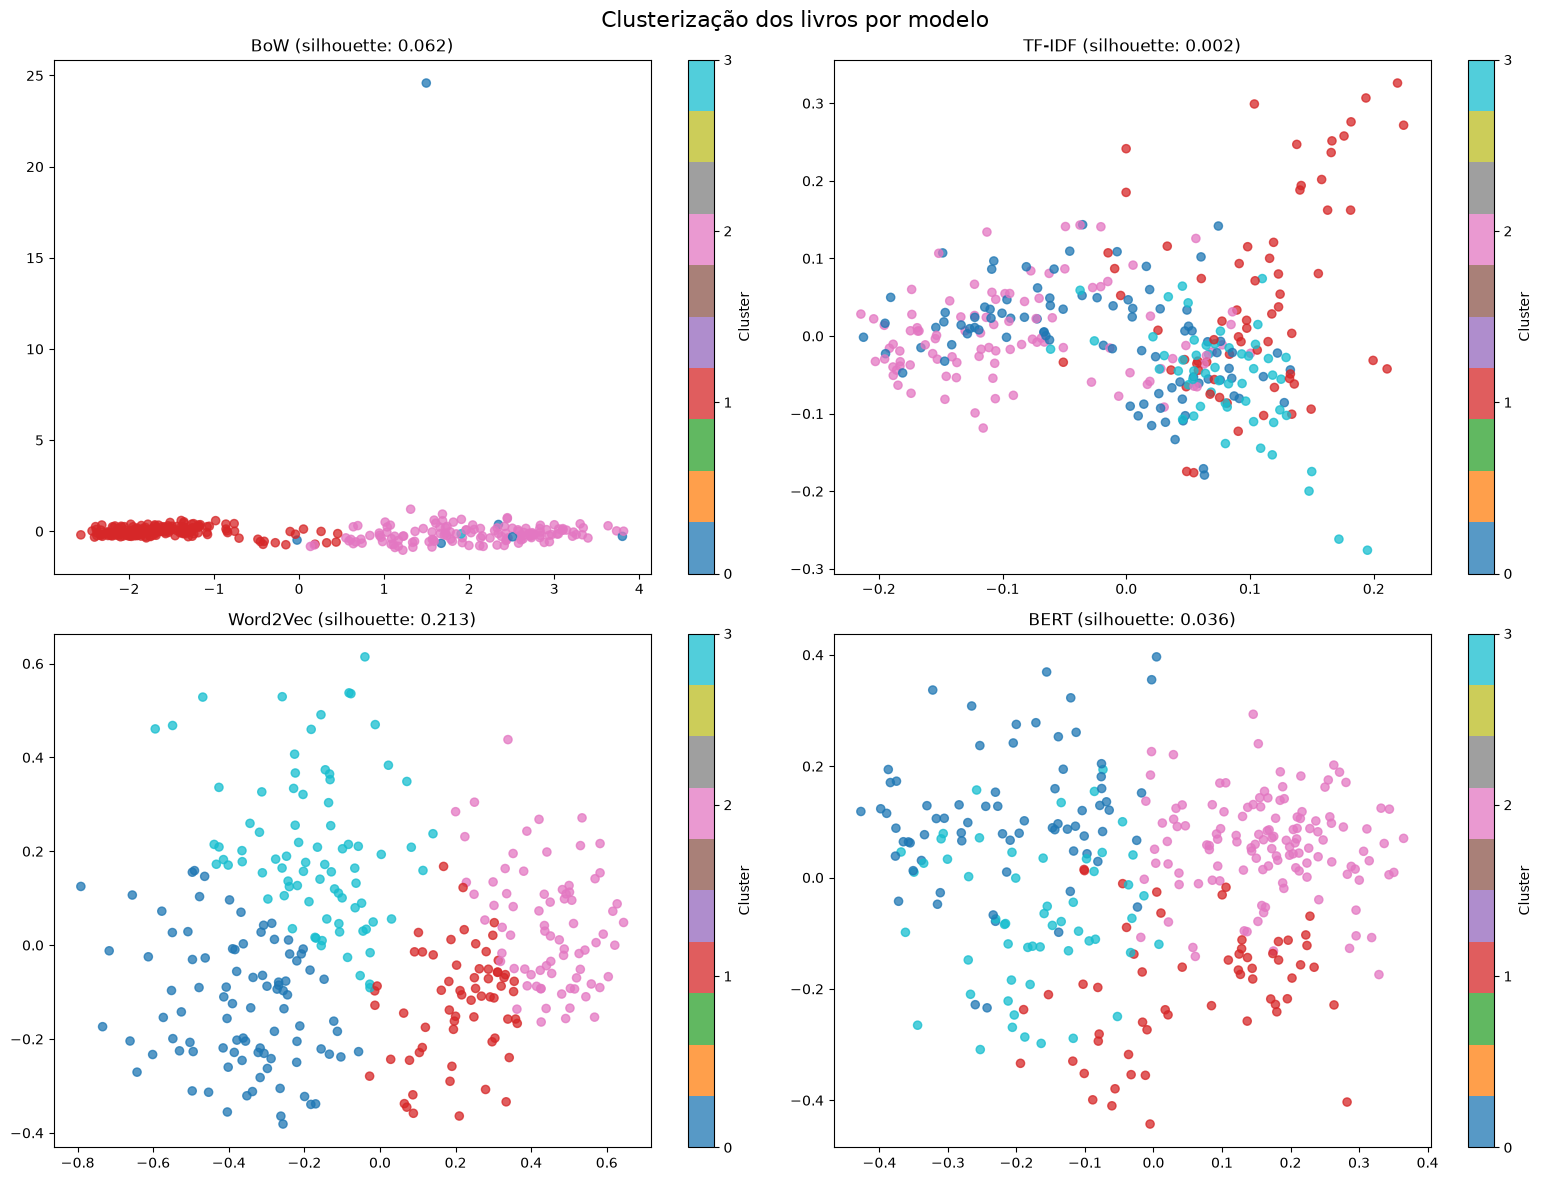

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (nome, resultado) in zip(axes.flat, resultados_clusterizacao.items()):
    coordenadas = resultado['coordenadas_pca']
    pontos = ax.scatter(
        coordenadas[:, 0],
        coordenadas[:, 1],
        c=resultado['clusters'],
        cmap='tab10',
        vmin=0,
        vmax=N_CLUSTERS - 1,
        alpha=0.75,
        s=35
    )
    ax.set_title(f"{nome} (silhouette: {resultado['silhouette']:.3f})")
    fig.colorbar(pontos, ax=ax, ticks=range(N_CLUSTERS), label='Cluster')

fig.suptitle('Clusterização dos livros por modelo', fontsize=16)
fig.tight_layout()
plt.show()